In [1]:
import os

# Windows Hadoop setup
if os.name == "nt":
    os.environ["HADOOP_HOME"] = r"C:\Hadoop\hadoop-3.3.5"
    os.environ["PATH"] = (
        os.path.join(os.environ["HADOOP_HOME"], "bin")
        + os.pathsep
        + os.environ["PATH"]
    )

print("HADOOP_HOME:", os.environ.get("HADOOP_HOME"))

HADOOP_HOME: C:\Hadoop\hadoop-3.3.5


In [2]:
from pyspark.sql import SparkSession

spark = (
    SparkSession.builder
    .master("local[*]")
    .appName("IND320SparkCassandra")
    .config(
        "spark.jars.packages",
        "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1"
    )
    .config("spark.cassandra.connection.host", "localhost")
    .config("spark.cassandra.connection.port", "9042")
    .config(
        "spark.sql.extensions",
        "com.datastax.spark.connector.CassandraSparkExtensions"
    )
    .config(
        "spark.sql.catalog.mycatalog",
        "com.datastax.spark.connector.datasource.CassandraCatalog"
    )
    .getOrCreate()
)

print("Spark version:", spark.version)

Spark version: 3.5.9


In [3]:
test_df = (
    spark.read
    .format("org.apache.spark.sql.cassandra")
    .options(
        keyspace="ind320_test",
        table="spark_test",
    )
    .load()
)

test_df.show()

+---+--------------------+
| id|               value|
+---+--------------------+
|  1|Spark-Cassandra c...|
+---+--------------------+



## 2. NVE Magasinstatistikk API

The reservoir statistics used in Compulsory Assignment 1 were loaded
from a local CSV file. In this assignment, the data are retrieved
directly from the NVE Magasinstatistikk API.

In [4]:
import requests
import pandas as pd

NVE_BASE_URL = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk"

In [5]:
areas_url = f"{NVE_BASE_URL}/HentOmråder"

response = requests.get(areas_url, timeout=30)
response.raise_for_status()

areas = response.json()

areas

[{'land': [{'navn': 'Norge',
    'navn_langt': 'Norge',
    'beskrivelse': 'Hele landet',
    'omrType': 'NO',
    'omrnr': 0}],
  'elspot': [{'navn': 'NO 1',
    'navn_langt': 'Elspotområde 1',
    'beskrivelse': 'Sørøst-Norge. Omfatter østlige del av Østlandet fra Buskerud og nordover (bortsett fra den del av Innlandet som ligger vest og nord for Vågåmo).',
    'omrType': 'EL',
    'omrnr': 1},
   {'navn': 'NO 2',
    'navn_langt': 'Elspotområde 2',
    'beskrivelse': 'Sørvest-Norge. Omfatter mesteparten av Vestfold, Telemark, Agder, Rogaland og sørlige del av Vestland.',
    'omrType': 'EL',
    'omrnr': 2},
   {'navn': 'NO 3',
    'navn_langt': 'Elspotområde 3',
    'beskrivelse': 'Midt-Norge. Omfatter nordre og vestlige del av Vestland, den del av Innlandet som ligger vest og nord for Vågåmo, Møre og Romsdal og Trøndelag til Tunnsjødal.',
    'omrType': 'EL',
    'omrnr': 3},
   {'navn': 'NO 4',
    'navn_langt': 'Elspotområde 4',
    'beskrivelse': 'Nord-Norge. Omfatter resten av

In [6]:
data_url = f"{NVE_BASE_URL}/HentOffentligData"

response = requests.get(data_url, timeout=30)
response.raise_for_status()

reservoir_data = response.json()

len(reservoir_data)

14922

In [7]:
reservoir_df = pd.DataFrame(reservoir_data)

reservoir_df.head()

,dato_Id,omrType,omrnr,iso_aar,iso_uke,fyllingsgrad,kapasitet_TWh,fylling_TWh,neste_Publiseringsdato,fyllingsgrad_forrige_uke,endring_fyllingsgrad
0,1995-09-03,EL,4,1995,35,0.944721,21.079208,19.913979,0001-01-01T00:00:00,0.936888,0.007833
1,2020-11-15,EL,1,2020,46,0.974361,6.003264,5.849344,2020-11-25T13:00:00,0.997406,-0.023046
2,2011-08-28,EL,4,2011,34,0.786499,21.079208,16.578772,0001-01-01T00:00:00,0.787193,-0.000694
3,1998-07-05,EL,3,1998,27,0.793969,8.920932,7.082947,0001-01-01T00:00:00,0.733812,0.060157
4,2011-03-27,EL,4,2011,12,0.300820,21.079208,6.341054,0001-01-01T00:00:00,0.311122,-0.010301


In [8]:
reservoir_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14922 entries, 0 to 14921
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   dato_Id                   14922 non-null  str    
 1   omrType                   14922 non-null  str    
 2   omrnr                     14922 non-null  int64  
 3   iso_aar                   14922 non-null  int64  
 4   iso_uke                   14922 non-null  int64  
 5   fyllingsgrad              14922 non-null  float64
 6   kapasitet_TWh             14922 non-null  float64
 7   fylling_TWh               14922 non-null  float64
 8   neste_Publiseringsdato    14922 non-null  str    
 9   fyllingsgrad_forrige_uke  14922 non-null  float64
 10  endring_fyllingsgrad      14922 non-null  float64
dtypes: float64(5), int64(3), str(3)
memory usage: 1.7 MB


In [10]:
reservoir_df = reservoir_df.rename(
    columns={
        "dato_Id": "date",
        "omrType": "area_type",
        "omrnr": "area_number",
        "iso_aar": "iso_year",
        "iso_uke": "iso_week",
        "fyllingsgrad": "fill_level",
        "kapasitet_TWh": "capacity_twh",
        "fylling_TWh": "stored_energy_twh",
        "neste_Publiseringsdato": "next_publication_date",
        "fyllingsgrad_forrige_uke": "previous_week_fill_level",
        "endring_fyllingsgrad": "change_in_fill_level",
    }
)

reservoir_df["date"] = pd.to_datetime(reservoir_df["date"])

reservoir_df["next_publication_date"] = (
    reservoir_df["next_publication_date"]
    .replace("0001-01-01T00:00:00", pd.NA)
)

reservoir_df["next_publication_date"] = pd.to_datetime(
    reservoir_df["next_publication_date"],
    errors="coerce",
)

reservoir_df = (
    reservoir_df
    .sort_values(["date", "area_type", "area_number"])
    .reset_index(drop=True)
)

reservoir_df.head()

,date,area_type,area_number,iso_year,iso_week,fill_level,capacity_twh,stored_energy_twh,next_publication_date,previous_week_fill_level,change_in_fill_level
0,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,NaT,0.583705,0.033869
1,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,NaT,0.777604,-0.146657
2,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,NaT,0.596027,0.006349
3,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,NaT,0.801348,-0.242484
4,1995-01-08,EL,5,1995,1,0.616448,17.390587,10.720388,NaT,0.614288,0.002160


In [11]:
reservoir_df.groupby("area_type")["area_number"].unique()

area_type
EL      [1, 2, 3, 4, 5]
NO                  [0]
VASS          [1, 2, 3]
Name: area_number, dtype: object

In [9]:
print(reservoir_df.columns.tolist())
print(reservoir_df["omrType"].unique())
print(reservoir_df["iso_aar"].min(), reservoir_df["iso_aar"].max())

['dato_Id', 'omrType', 'omrnr', 'iso_aar', 'iso_uke', 'fyllingsgrad', 'kapasitet_TWh', 'fylling_TWh', 'neste_Publiseringsdato', 'fyllingsgrad_forrige_uke', 'endring_fyllingsgrad']
<ArrowStringArray>
['EL', 'NO', 'VASS']
Length: 3, dtype: str
1995 2026


In [12]:
national_data = (
    reservoir_df[
        (reservoir_df["area_type"] == "NO")
        & (reservoir_df["area_number"] == 0)
    ]
    .sort_values("date")
    .copy()
)

national_data.head()

,date,area_type,area_number,iso_year,iso_week,fill_level,capacity_twh,stored_energy_twh,next_publication_date,previous_week_fill_level,change_in_fill_level
5,1995-01-08,NO,0,1995,1,0.607988,87.43758,53.161003,NaT,0.752631,-0.144643
14,1995-01-15,NO,0,1995,2,0.582088,87.43758,50.896374,NaT,0.607988,-0.025900
23,1995-01-22,NO,0,1995,3,0.562121,87.43758,49.150486,NaT,0.582088,-0.019967
32,1995-01-29,NO,0,1995,4,0.534222,87.43758,46.711033,NaT,0.562121,-0.027899
41,1995-02-05,NO,0,1995,5,0.506221,87.43758,44.262720,NaT,0.534222,-0.028001


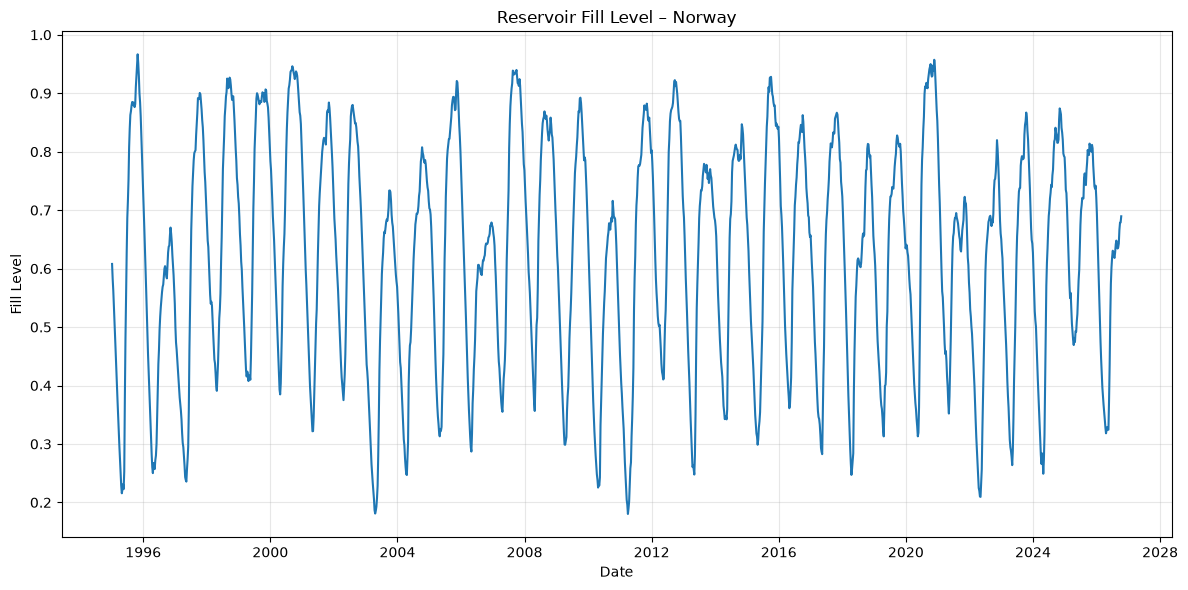

In [13]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    national_data["date"],
    national_data["fill_level"],
)

ax.set_title("Reservoir Fill Level – Norway")
ax.set_xlabel("Date")
ax.set_ylabel("Fill Level")
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## 7. MongoDB

The MongoDB Atlas connection is stored securely in a local `.env`
file and is not included in the GitHub repository.

In [14]:
import os

from dotenv import load_dotenv
from pymongo import MongoClient

load_dotenv()

mongodb_uri = os.getenv("MONGODB_URI")

client = MongoClient(mongodb_uri)

# Test connection
client.admin.command("ping")

print("MongoDB connection successful.")

MongoDB connection successful.


In [15]:
db = client["ind320"]
collection = db["connection_test"]

test_document = {
    "source": "IND320",
    "message": "MongoDB connection works",
}

result = collection.insert_one(test_document)

print("Inserted document ID:", result.inserted_id)

Inserted document ID: 6ad524646e64a8106365a540


In [16]:
document = collection.find_one(
    {"message": "MongoDB connection works"}
)

document

{'_id': ObjectId('6ad524646e64a8106365a540'),
 'source': 'IND320',
 'message': 'MongoDB connection works'}

In [17]:
delete_result = collection.delete_one(
    {"message": "MongoDB connection works"}
)

print("Deleted documents:", delete_result.deleted_count)

Deleted documents: 1


In [18]:
client.close()